In [4614]:
import numpy as np
import pandas as pd
import random

In [4615]:
###NOTE NOTE NOTE

#this is first running the base model at the beginning of the day (no - disruption)
#then based on DST (disruption start time) determining the remaining nodes (both the truck and the drone nodes)
#determining the truck and the drone location at the time of DST
#since after the disruption it is not a TSP rather it is a hamiltonian path, we need to add a dummy node for concorde solution
#we add this dummy node 
#then we get the concorde solution 
#we delete the dummy node from the concorde TSP solution and provide this concorde solution to the disruption scenario as an input
#then we run the disruption scenario and check the feasibility (currently this part is not in this notebook) 


In [4616]:
#############details of the code CCCC

In [4617]:
def t_pathcost(route, V):
    """
    Calculates total travel time for a truck-only TSP route.

    Parameters:
    - route: list of node indices in order (e.g., [0, 2, 3, 1])
    - V: dictionary mapping node index to (x, y) coordinates

    Returns:
    - Total truck travel time (float)
    """

    total = 0
    n = len(route)
    
    for i in range(n):
        current_node = route[i]
        next_node = route[(i + 1) % n]  # Loop back to start
        total += t_cost(V[current_node], V[next_node])
    
    return total


In [4618]:
#generating_functions.py
#This file contains functions to generate test cases — that is, sets of coordinates for the depot and customer nodes used in TSP-D problems.
def generate_coordinates_square(n, lower=0, upper=100):
    """
    Generates `n` random 2D coordinates within a square [lower, upper] x [lower, upper].

    Parameters:
    - n: number of customer locations (excluding depot)
    - lower: lower bound of coordinate values
    - upper: upper bound of coordinate values

    Returns:
    - V: dictionary of node index to (x, y) coordinates
         depot is always assigned index 0
    """
    V = {0: (random.uniform(lower, upper), random.uniform(lower, upper))}  # depot

    for i in range(1, n + 1):
        V[i] = (random.uniform(lower, upper), random.uniform(lower, upper))

    return V


In [4619]:
generate_coordinates_square(n=5, lower=0, upper=20)

{0: (16.888437030500963, 15.159088058806049),
 1: (8.4114316166169, 5.178335005859267),
 2: (10.22549442737217, 8.098682749008287),
 3: (15.675971780695452, 6.066254521578549),
 4: (9.531939083047117, 11.667640789100624),
 5: (18.162257703906704, 10.093737116347805)}

In [4620]:
V1 = [[8.54, 8.39],
 [19.45, 8.22],
 [7.8, 6.87],
 [3.02, 9.12],
 [4.38, 18.52],
 [16.34, 11.19],
 [6.59, 13.9],
 [18.25, 18.25],
 [11.49, 13.2],
 [11.59, 4.13],
 [8.37, 4.23],
 [12.73, 3.45],
 [13.01, 1.27],
 [9.97, 11.75],
 [2.72, 10.95],
 [4.13, 18.5],
 [2.6, 17.87],
 [10.04, 2.25],
 [5.36, 13.97],
 [9.55, 8.07],
 [13.95, 8.88],
 [15.54, 2.51],
 [2.58, 3.44],
 [7.69, 0.12],
 [4.09, 4.84],
 [16.42, 11.49],
 [16.01, 13.68],
 [18.07, 19.09],
 [15.49, 10.08],
 [17.53, 19.38],
 [3.17, 17.41],
 [18.07, 7.6],
 [12.48, 12.46],
 [6.54, 11.67],
 [3.1, 11.03],
 [15.23, 12.93],
 [16.37, 19.25],
 [8.83, 16.4],
 [8.79, 10.76],
 [9.35, 15.1],
 [12.64, 19.54],
 [19.53, 5.59],
 [0.45, 18.87],
 [17.06, 11.89],
 [15.6, 5.47],
 [19.89, 10.87],
 [10.86, 16.76],
 [14.76, 9.92],
 [3.35, 0.44],
 [12.77, 17.54],
 [2.94, 7.37],
 [0.97, 14.58],
 [11.97, 11.49],
 [9.7, 0.34],
 [16.31, 5.09],
 [10.97, 5.05],
 [7.31, 14.85],
 [14.62, 14.6],
 [7.31, 4.45],
 [18.87, 7.98],
 [12.36, 13.09],
 [12.98, 12.15],
 [4.55, 1.82],
 [6.32, 16.37],
 [7.97, 3.39],
 [13.18, 4.28],
 [5.44, 0.92],
 [17.2, 16.06],
 [0.67, 2.03],
 [8.79, 6.44],
 [5.54, 6.81],
 [16.64, 10.67],
 [18.79, 3.08],
 [19.24, 6.31],
 [9.05, 16.95],
 [19.53, 1.46],
 [15.75, 9.41],
 [14.0, 10.83],
 [8.11, 0.18],
 [1.14, 11.54],
 [14.24, 7.49],
 [2.15, 4.4],
 [2.26, 3.84],
 [16.46, 0.31],
 [15.39, 16.24],
 [5.41, 6.37],
 [1.6, 11.6],
 [2.51, 15.07],
 [2.72, 18.33],
 [4.78, 2.2],
 [15.53, 8.68],
 [0.35, 9.82],
 [19.63, 16.67],
 [11.23, 1.32],
 [9.2, 0.75],
 [6.78, 0.18],
 [16.0, 1.56],
 [1.18, 13.07],
 [10.04, 0.38],
 [10.2, 12.02],
 [12.32, 8.12],
 [8.54, 8.39]]

In [4621]:
tsp1 = [0,
 19,
 38,
 13,
 99,
 8,
 60,
 32,
 52,
 61,
 77,
 47,
 28,
 76,
 90,
 20,
 100,
 80,
 44,
 54,
 21,
 96,
 83,
 75,
 72,
 41,
 73,
 31,
 59,
 1,
 45,
 71,
 25,
 5,
 43,
 26,
 35,
 57,
 84,
 67,
 92,
 7,
 27,
 29,
 36,
 40,
 49,
 46,
 37,
 74,
 39,
 56,
 6,
 33,
 18,
 63,
 15,
 4,
 30,
 16,
 42,
 88,
 87,
 51,
 97,
 86,
 79,
 34,
 14,
 91,
 3,
 50,
 85,
 70,
 24,
 81,
 22,
 82,
 68,
 48,
 62,
 89,
 66,
 95,
 23,
 78,
 53,
 98,
 94,
 17,
 93,
 12,
 11,
 65,
 9,
 55,
 10,
 64,
 58,
 69,
 2,
 101]


In [4622]:
len(tsp1)  #AABB

102

In [4623]:
Reg = []

for (x, y) in V1:  # each node is a tuple (x,y)

    if 0 <= x <= 4:
        Reg.append(1)

    elif 4 < x <= 8:
        Reg.append(2)

    elif 8 < x <= 12:
        Reg.append(3)

    elif 12 < x <= 16:
        Reg.append(4)

    elif 16 < x <= 20:
        Reg.append(5)

    else:
        Reg.append(None)   # optional: if outside region definitions
Reg


[3,
 5,
 2,
 1,
 2,
 5,
 2,
 5,
 3,
 3,
 3,
 4,
 4,
 3,
 1,
 2,
 1,
 3,
 2,
 3,
 4,
 4,
 1,
 2,
 2,
 5,
 5,
 5,
 4,
 5,
 1,
 5,
 4,
 2,
 1,
 4,
 5,
 3,
 3,
 3,
 4,
 5,
 1,
 5,
 4,
 5,
 3,
 4,
 1,
 4,
 1,
 1,
 3,
 3,
 5,
 3,
 2,
 4,
 2,
 5,
 4,
 4,
 2,
 2,
 2,
 4,
 2,
 5,
 1,
 3,
 2,
 5,
 5,
 5,
 3,
 5,
 4,
 4,
 3,
 1,
 4,
 1,
 1,
 5,
 4,
 2,
 1,
 1,
 1,
 2,
 4,
 1,
 5,
 3,
 3,
 2,
 4,
 1,
 3,
 3,
 4,
 3]

In [4624]:
#9999 BBBB
#DST50
#TCon =  [[0, 0], [50,62],[62,74],[74,86],[86,98],[98,110]]#disruption duration 
#TCon =  [[0, 0], [50,74],[74,98],[98,122],[122,146],[146,170]]#disruption duration 
#TCon =  [[0, 0], [50,86],[86,122],[122,158],[158,194],[194,230]]#disruption duration 

#DST125
#TCon =  [[0, 0], [125,137],[137,149],[149,161],[161,173],[173,185]]#DUR60
#TCon =  [[0, 0], [125,149],[149,173],[173,197],[197,221],[221,245]]#DUR120
#TCon =  [[0, 0], [125,161],[161,197],[197,233],[233,269],[269,305]]#DUR180

#DST200
#TCon =  [[0, 0], [200,212],[212,224],[224,236],[236,248],[248,260]]#DUR60
#TCon =  [[0, 0], [200,224],[224,248],[248,272],[272,296],[296,320]]#DUR120
TCon =  [[0, 0], [200,236],[236,272],[272,308],[308,344],[344,380]]#DUR180

#TOTAL DISRUPTION
#TCon =  [[0, 0], [0,60],[0,60],[0,60],[0,60],[0,60]]#TOTAL1
#TCon =  [[0, 0], [0,120],[0,120],[0,120],[0,120],[0,120]]#TOTAL1
#TCon =  [[0, 0], [0,180],[0,180],[0,180],[0,180],[0,180]]#TOTAL1

#TCon =  [[0, 0], [0,0],[0,0],[0,0],[0,0],[0,0]]#disruption duration #FOR COMPARISON

In [4625]:
START = TCon[1][0]
DURATION = TCon[5][1] - TCon[1][0]
START, DURATION

(200, 180)

In [4626]:
# https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/solving_TSP.py
#this is named solving_TSP.py
import heapq
from basic_functions2 import t_cost
import itertools

## these algorithms return the routes

# 2-approximation algorithm using minimum spanning tree
def two_approximation_for_TSP(V):
    n = len(V)
    #prim
    mst = {i:[] for i in range(n)} # MST の隣接リスト
    X = set()
    heap = []
    for i in range(1,n):
        heapq.heappush(heap,(t_cost(V[0],V[i]),0,i))
    while len(heap)>0:
        (d,u,i)=heapq.heappop(heap)
        if i not in X:
            X.add(i)
            mst[u].append(i)
            mst[i].append(u)
            for w in range(n):
                if w not in X: heapq.heappush(heap,(t_cost(V[i],V[w]),i,w))
    #dfs
    res = []
    stack = [0]
    visited = [False]*n
    while len(stack)>0:
        i = stack.pop()
        if visited[i]: continue
        visited[i]=True
        res.append(i)
        for u in mst[i]: stack.append(u)
    return res

# 2-opt algorithm using edge swap
def two_opt_for_TSP(V):
    n = len(V)
    res = list(range(n))
    update = True
    while update:
        update = False
        for (i,j) in itertools.combinations(range(n),2):
            if ((t_cost(V[res[i]],V[res[i+1]])+t_cost(V[res[j]],V[res[(j+1)%n]]))>
                (t_cost(V[res[i]],V[res[j]])+t_cost(V[res[i+1]],V[res[(j+1)%n]]))):
                res[i+1:j+1] = res[j:i:-1]
                update = True
    return res

# dynamic programming
def DP_for_TSP(V):
    length = {} # length[(u,S)]: u を始点とし S の点すべてを回る最小経路長、ディクショナリ
    route = {} # route[(u,S)]: 最小経路長を達成するためのルート、ディクショナリ
    v = V[0]
    n = len(V)
    for i in range(1,n+1):
        for a in itertools.combinations(range(n),i):
            S = frozenset(a)
            for j in S:
                u = V[j]
                if i==1:
                    length[(j,S)] = t_cost(v,u)
                    route[(j,S)] = [j]
                else:
                    Sj = S-set([j]) # S から j を除いたもの
                    k=min(Sj,key=lambda k: length[(k,Sj)]+t_cost(V[k],u))#Sjの中でlength[(k,Sj)]+dist(V[k],u)が最小のものを返している
                    length[(j,S)] = length[(k,Sj)]+t_cost(V[k],u)
                    route[(j,S)] = route[(k,Sj)]+[j]
    return route[(0,frozenset(range(n)))]

In [4627]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/route_drawing.py
##this is named route_drawing.py
import matplotlib.pyplot as plt

# red for truck, blue for drone
def drawing_routes_for_DP(V,path,depot,drone_nodes):
  n = len(V)
  text_dict = dict(boxstyle = "round",fc = "silver", ec = "mediumblue")
  for i in range(n):
      plt.scatter(V[depot][0],V[depot][1],c='k')
      plt.annotate("DEPOT",size = 6, xy = (V[depot][0],V[depot][1]), bbox = text_dict)
      plt.scatter(V[i][0],V[i][1],c='k')
      if i in drone_nodes:
        plt.annotate(f"d{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
      elif i != 0:
        plt.annotate(f"t{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
  for i in range(len(path)):
      if len(path[i])>=3:
          for j in range(len(path[i])-2):
              truck_x=[V[path[i][j]][0],V[path[i][j+1]][0]]
              truck_y=[V[path[i][j]][1],V[path[i][j+1]][1]]
              plt.plot(truck_x, truck_y,c='red')
          truck_x=[V[path[i][-2]][0],V[path[(i+1)%len(path)][0]][0]]
          truck_y=[V[path[i][-2]][1],V[path[(i+1)%len(path)][0]][1]]
          drone_x1=[V[path[i][0]][0],V[path[i][-1][0]][0]]
          drone_y1=[V[path[i][0]][1],V[path[i][-1][0]][1]]
          drone_x2=[V[path[i][-1][0]][0],V[path[i][-2]][0]]
          drone_y2=[V[path[i][-1][0]][1],V[path[i][-2]][1]]
          plt.plot(truck_x,truck_y,c='red')
          plt.plot(drone_x1,drone_y1, c='blue')
          plt.plot(drone_x2,drone_y2, c='blue')
      elif len(path[i])==1:
          truck_x=[V[path[i][0]][0],V[path[i+1][0]][0]]
          truck_y=[V[path[i][0]][1],V[path[i+1][0]][1]]
          plt.plot(truck_x,truck_y, c='red')
      else:
          truck_x=[V[path[i][-2]][0],V[path[(i+1)%len(path)][0]][0]]
          truck_y=[V[path[i][-2]][1],V[path[(i+1)%len(path)][0]][1]]
          drone_x1=[V[path[i-1][0]][0],V[path[i][-1][0]][0]]
          drone_y1=[V[path[i-1][0]][1],V[path[i][-1][0]][1]]
          drone_x2=[V[path[i][-1][0]][0],V[path[i][-2]][0]]
          drone_y2=[V[path[i][-1][0]][1],V[path[i][-2]][1]]
          plt.plot(truck_x,truck_y,c='red')
          plt.plot(drone_x1,drone_y1, c='blue')
          plt.plot(drone_x2,drone_y2, c='blue')
  plt.show()

def drawing_routes_using_labels(V,label,depot,drone_nodes):
    tsp_route = [i for i in label.keys()]
    n = len(V)
    text_dict = dict(boxstyle = "round",fc = "silver", ec = "mediumblue")
    for i in range(n):
        plt.scatter(V[depot][0],V[depot][1],c='k')
        plt.annotate("DEPOT",size = 6, xy = (V[depot][0],V[depot][1]), bbox = text_dict)
        plt.scatter(V[i][0],V[i][1],c='k')
        if i in drone_nodes:
          plt.annotate(f"d{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
        elif i != 0:
          plt.annotate(f"t{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
    for i in range(n):
      if label[tsp_route[i]] == "combined":
        if label[tsp_route[(i+1)%n]] == "combined":
          truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+1)%n]][0])
          truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+1)%n]][1])
          plt.plot(truck_x,truck_y,c="red")
        else:
          cnt = 1
          while label[tsp_route[(i+cnt)%n]] != "drone":
            cnt += 1
          drone_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
          drone_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
          plt.plot(drone_x,drone_y,c="blue")
          cnt = 1
          while label[tsp_route[(i+cnt)%n]] == "drone":
            cnt += 1
          truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
          truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
          plt.plot(truck_x,truck_y,c="red")
      elif label[tsp_route[i]] == "drone":
        cnt = 1
        while label[tsp_route[(i+cnt)%n]] != "combined":
          cnt += 1
        drone_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
        drone_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
        plt.plot(drone_x,drone_y,c="blue")
      else:
        cnt = 1
        while label[tsp_route[(i+cnt)%n]] == "drone":
          cnt += 1
        truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
        truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
        plt.plot(truck_x,truck_y,c="red")  
    plt.show()

In [4628]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/generating_functions.py
##named generating_functions.py
import random
import math
import numpy
random.seed(0)

# customers are located uniformly
def testcase_uniform(n):
    V=[(random.uniform(0,100),random.uniform(0,100)) for i in range(n)]
    return V

# customers are located in the shape of donut
def testcase_donuts(n):
    V=[]
    for i in range(n):
        angle=random.uniform(0,2*math.pi)
        V.append((25*random.uniform(0.9,1.1)*math.cos(angle)+50,25*random.uniform(0.9,1.1)*math.sin(angle)+50))
    return V

# customers are located in the shape of donuts but depot is in the center
def testcase_donuts_center(n):
    V=[(50,50)]
    for i in range(n-1):
        angle=random.uniform(0,2*math.pi)
        V.append((25*random.uniform(0.9,1.1)*math.cos(angle)+50,25*random.uniform(0.9,1.1)*math.sin(angle)+50))
    return V

# customers are located in more in center but less in outsides
def testcase_center(n):
    V=[]
    for i in range(n):
        angle=random.uniform(0,2*math.pi)
        r=numpy.random.normal(0,25)
        V.append((r*math.cos(angle)+50,r*math.sin(angle)+50))
    return V

In [4629]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/heuristics/iterative_improvement_procedure.py
#named iterative_improvement_procedure.py

import itertools

# iとjの順番を入れ替える
# swap index i and j
def two_points_move(lis,i,j):
    if i<j:
      new_list=lis[:i]+[lis[j]]+lis[(i+1):j]+[lis[i]]+lis[(j+1):]
    else:
      new_list=lis[:j]+[lis[i]]+lis[(j+1):i]+[lis[j]]+lis[(i+1):]
    return new_list

# 2辺を入れ替える
# swap two edges
def two_opt_move(lis,i,j):
    if i<j:
      new_list=lis[:i+1]+lis[j:(i+1)%len(lis)-1:-1]+lis[(j+1):]
    else:
      new_list=[lis[i]]+lis[j::-1]+lis[:(i+1)%len(lis)-1:-1]+lis[j+1:i]
    return new_list

# iをj番目に挿入する
# insert i to j
def one_point_move(lis,i,j):
    if i<j:
      new_list=lis[:i]+lis[(i+1):(j+1)]+[lis[i]]+lis[(j+1):]
    else:
      new_list=lis[:j]+[lis[i]]+lis[j:i]+lis[(i+1):]
    return new_list

# improving procedure using one of the moves
def improve(move,heuristic,lis,depot,V,alpha):
    n=len(lis)
    initial=lis
    f=heuristic(initial,depot)[0]
    update=True
    while update:
        update=False
        for (i,j) in itertools.permutations(range(n),2):
            newroute=move(lis,i,j)
            if f>heuristic(V,newroute,depot,alpha)[0]:
                update=True
                initial=newroute
                f=heuristic(V,newroute,depot,alpha)[0]
        if update:
            lis=initial
    return initial

# improving procedure using all of the moves
'''
def improve_all(heuristic,lis,depot,V,alpha):
    n=len(lis)
    initial=lis
    f=heuristic(V,initial,depot,alpha)[0]
    update=True
    while update:
        update=False
        for (i,j) in itertools.permutations(range(n),2):
            #moves=[two_points_move(lis,i,j),two_opt_move(lis,i,j),one_point_move(lis,i,j)]
            moves=[one_point_move(lis,i,j)] #v1 we want it to use only one-point move so updated
            for newroute in moves:
                if f>heuristic(V,newroute,depot,alpha)[0]:
                    update=True
                    initial=newroute
                    f=heuristic(V,newroute,depot,alpha)[0]
        if update:
            lis=initial
    return initial
'''


'\ndef improve_all(heuristic,lis,depot,V,alpha):\n    n=len(lis)\n    initial=lis\n    f=heuristic(V,initial,depot,alpha)[0]\n    update=True\n    while update:\n        update=False\n        for (i,j) in itertools.permutations(range(n),2):\n            #moves=[two_points_move(lis,i,j),two_opt_move(lis,i,j),one_point_move(lis,i,j)]\n            moves=[one_point_move(lis,i,j)] #v1 we want it to use only one-point move so updated\n            for newroute in moves:\n                if f>heuristic(V,newroute,depot,alpha)[0]:\n                    update=True\n                    initial=newroute\n                    f=heuristic(V,newroute,depot,alpha)[0]\n        if update:\n            lis=initial\n    return initial\n'

In [4630]:
##############details of the code 

In [4631]:
#5555
##new updated one (travel times) 
def compute_truck_times_manhattan(V):
    n = len(V)
    tT = {}
    for i in range(n):
        xi, yi = V[i]
        for j in range(n):
            xj, yj = V[j]
            dist_ij = abs(xi - xj) + abs(yi - yj)
            tT[(i, j)] = float(dist_ij)
            tT[(i, j)] = ((float(dist_ij))*60)/25
    return tT


def compute_drone_times_euclidean(V, alpha=1.0):
    n = len(V)
    dT = {}
    for i in range(n):
        xi, yi = V[i]
        for j in range(n):
            xj, yj = V[j]
            dx = xi - xj
            dy = yi - yj
            dist_ij = (dx*dx + dy*dy) ** 0.5
            #dT[(i, j)] = (float(alpha * dist_ij))*60
            dT[(i, j)] = ((float(alpha * dist_ij))*60)/35
    return dT


In [4632]:
alpha = 1.0
tT = compute_truck_times_manhattan(V1)
dT = compute_drone_times_euclidean(V1,alpha = 1)
tT

{(0, 0): 0.0,
 (0, 1): 26.592,
 (0, 2): 5.4239999999999995,
 (0, 3): 14.999999999999995,
 (0, 4): 34.296,
 (0, 5): 25.44,
 (0, 6): 17.904,
 (0, 7): 46.968,
 (0, 8): 18.624,
 (0, 9): 17.544000000000004,
 (0, 10): 10.392000000000001,
 (0, 11): 21.912000000000006,
 (0, 12): 27.816000000000003,
 (0, 13): 11.496000000000002,
 (0, 14): 20.111999999999995,
 (0, 15): 34.848,
 (0, 16): 37.008,
 (0, 17): 18.336000000000002,
 (0, 18): 21.023999999999997,
 (0, 19): 3.1920000000000046,
 (0, 20): 14.16,
 (0, 21): 30.912000000000003,
 (0, 22): 26.184,
 (0, 23): 21.888,
 (0, 24): 19.2,
 (0, 25): 26.352000000000007,
 (0, 26): 30.624000000000006,
 (0, 27): 48.552,
 (0, 28): 20.736000000000004,
 (0, 29): 47.952,
 (0, 30): 34.536,
 (0, 31): 24.768000000000008,
 (0, 32): 19.224000000000004,
 (0, 33): 12.671999999999995,
 (0, 34): 19.391999999999996,
 (0, 35): 26.952,
 (0, 36): 44.856,
 (0, 37): 19.919999999999998,
 (0, 38): 6.2879999999999985,
 (0, 39): 18.048,
 (0, 40): 36.6,
 (0, 41): 33.09600000000001,


In [4633]:
OnlyTruck = 0
for i in range (len(tsp1) -1):
    OnlyTruck += tT[tsp1[i],tsp1[i+1]]
OnlyTruck
    

491.9039999999999

In [4634]:
##THIS IS MY OWN DEFINITION OF COST FUNCTIONS
#THIS IS UPDATED t-cost and d-cost

# cost(time) of trucks
def t_cost(s, t):
    return ((60/25)*(abs(s[0] - t[0]) + abs(s[1] - t[1])))
    
# cost(time) of drones
def d_cost(s,t,alpha): 
  return (1/alpha)*(60/35)*(((s[0]-t[0])**2+(s[1]-t[1])**2)**(0.5))

## t_cost > d_cost holds


def t_pathcost(a,b,route,V):
    pathcost=0
    if a<b:
        for i in range(a,b):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
    if a>b:
        for i in range(a,len(route)):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
        for i in range(b):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
    if a==b:
        pathcost=0
            
    return pathcost

In [4635]:

# cost(time) of trucks
def t_cost(s, t):
    return ((60/25)*(abs(s[0] - t[0]) + abs(s[1] - t[1])))
    
# cost(time) of drones
def d_cost(s,t,alpha): 
  return (1/alpha)*(60/35)*(((s[0]-t[0])**2+(s[1]-t[1])**2)**(0.5))


In [4636]:
#############

In [4637]:
'''
# # ================================
# TSP-D base model (requires ready tT/dT)
# Greedy partition (MakeFly/PushLeft/PushRight)
# Schedule + True Makespan (truck path + waits + SL + SR)
# PERFECT INFORMATION version:
#   - Regional disruption constraints imposed FROM THE START (using Reg, TCon)
#   - NO DRN (Drone Rescue Node) constraint
# Assumes you define BEFORE running:
#   V1, tsp1 (Concorde tour), tT, dT, Reg, TCon
# ================================

import sys, time as _time
import numpy as _np
import numpy
from collections import OrderedDict, defaultdict
from typing import Dict, Tuple, List

# ---------- Reproducibility ----------
#SEED = 1389 spare
#SEED = 1040 #rep1 
#SEED = 7878 #rep2
#SEED = 330 #rep3
#SEED = 1018 #rep4
#SEED = 1923 #rep5

SAMPLE_RATIO = 0.05  # for tour local search (sampled neighbors)

# ---------- Service times ----------
SL = 1.0   # launch service (0 at depot)
SR = 1.0   # recovery service at rendezvous

# ---------- Mission energy/feasibility limit (time) ----------
E_LIMIT = 40.0

# ---------- Optional drawing ----------
DRAW_ROUTES = True
sys.path.append("../")
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Travel-time accessors (REQUIRES ready tT/dT)
# =========================================================
def _ensure_travel_times():
    global tT, dT
    assert isinstance(tT, dict) and isinstance(dT, dict), \
        "You must predefine ready dicts tT and dT before running."

def truck_time(i, j):  # symmetric lookup ok
    try: return tT[(i, j)]
    except KeyError: return tT[(j, i)]

def drone_time(i, j):
    try: return dT[(i, j)]
    except KeyError: return dT[(j, i)]

# =========================================================
# PERFECT-INFO DISRUPTION CHECKS (Reg, TCon must exist)
# =========================================================
def _ensure_disruption_data():
    global Reg, TCon, V1
    assert "Reg" in globals() and Reg is not None, "Define Reg (region index per node) before running."
    assert "TCon" in globals() and TCon is not None, "Define TCon (region -> (start,end)) before running."
    assert len(Reg) == len(V1), "Reg must have length len(V1)."

def is_in_disruption(region_idx, t):
    """
    True if time t is inside the disruption window of region_idx.
    Region 0 / None = no disruption.
    """
    if region_idx is None or region_idx <= 0:
        return False
    start, end = TCon[region_idx]
    return (t >= start) and (t <= end)

def disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
    """
    Enforce regional disruption constraints at the beginning (perfect information).
    We require that key event times are NOT inside disruption windows:
      - launch completion time at L  (drone_times[L][1])
      - drone arrival at drone customer d (drone_times[d][0])
      - drone arrival at rendezvous R (drone_times[R][0])
    """
    _ensure_disruption_data()
    global Reg

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            return False

        # launch completion time at L (after SL)
        if is_in_disruption(Reg[L], drone_times[L][1]):
            return False
        # drone arrival to customer
        if is_in_disruption(Reg[d], drone_times[d][0]):
            return False
        # drone arrival to rendezvous
        if is_in_disruption(Reg[R], drone_times[R][0]):
            return False

    return True

# =========================================================
# Greedy partition: MakeFly / PushLeft / PushRight
# (UPDATED: checks disruption feasibility after each accepted move)
# =========================================================
def greedy_partitioning(tsp, depot, V1):
    """
    Build TSP-D partition on a fixed truck-only TSP tour 'tsp'.
    Returns: (tspd_total, label, drone_nodes, drone_mission, operation, flyop, driveop)
    """
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(tsp)
    end_depot = len(V1) - 1

    # Forbidden drone-only customers: keep your old set logic if needed
    ND =  {4, 5, 10, 15, 20, depot, end_depot}

    label = {}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}  # d -> (L,R)

    # base truck tour cost around cycle
    tsptotal = 0.0
    for k in range(n):
        i, j = tsp[k], tsp[(k + 1) % n]
        label[i] = 'simple'
        tsptotal += truck_time(i, j)
    tspdtotal = tsptotal

    # attempt cap to avoid infinite loops if disruption blocks all improvements
    MAX_ATTEMPTS_PER_OUTER = max(10, 10 * n)

    while 'simple' in label.values():
        banned = set()      # (block,pos) pairs that were tried and violated disruption
        attempts = 0

        while True:
            attempts += 1
            if attempts > MAX_ATTEMPTS_PER_OUTER:
                # give up improving: finalize remaining as combined
                for u in label:
                    if label[u] == 'simple':
                        label[u] = 'combined'
                break

            ms = []
            idx_map = []  # maps each appended saving to (block,pos)

            # 1) Make Fly
            for i in range(n):
                if (0, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((0, i))
                    continue

                saving = -float('inf')
                u = tsp[i]
                if label[u] == 'simple' and u not in ND:
                    L = tsp[i - 1]
                    R = tsp[(i + 1) % n]
                    fly_time = drone_time(L, u) + drone_time(u, R)

                    if fly_time + SL <= E_LIMIT and truck_time(L, R) <= E_LIMIT:
                        base = truck_time(L, u) + truck_time(u, R)
                        alt  = max(fly_time, truck_time(L, R) + SL + SR)
                        saving = base - alt

                ms.append(saving)
                idx_map.append((0, i))

            # 2) Push Left
            for i in range(n):
                if (1, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((1, i))
                    continue

                saving = -float('inf')
                cur = tsp[i]
                prev = tsp[i - 1]
                if label.get(prev) == 'combined' and prev != depot and label.get(cur) == 'simple':
                    j = i - 2
                    dronenode = None
                    while label[tsp[j]] != 'combined':
                        if label[tsp[j]] == 'drone':
                            dronenode = j
                        if label[tsp[j - 1]] == 'combined' and dronenode is not None:
                            d = tsp[dronenode]
                            L = tsp[j - 1]
                            R_old = prev
                            R_new = cur
                            base_key = (d, L, R_old)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new   = drone_time(L, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(R_old, R_new)
                                if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                    saving = truck_time(R_old, R_new) + operation[base_key] - \
                                             max(fly_new, drive_new + SR)
                            break
                        j -= 1

                ms.append(saving)
                idx_map.append((1, i))

            # 3) Push Right
            for i in range(n):
                if (2, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((2, i))
                    continue

                saving = -float('inf')
                cur = tsp[i]
                nxt = tsp[(i + 1) % n]
                if label.get(nxt) == 'combined' and nxt != depot and label.get(cur) == 'simple':
                    j = (i + 2) % n
                    dronenode = None
                    while label[tsp[j]] != 'combined':
                        if label[tsp[j]] == 'drone':
                            dronenode = j
                        if label[tsp[(j + 1) % n]] == 'combined' and dronenode is not None:
                            d = tsp[dronenode]
                            L_old = nxt
                            R_new = tsp[(j + 1) % n]
                            base_key = (d, L_old, R_new)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new   = drone_time(cur, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(cur, L_old)
                                if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                    saving = truck_time(cur, L_old) + operation[base_key] - \
                                             max(fly_new, drive_new + SR)
                            break
                        j = (j + 1) % n

                ms.append(saving)
                idx_map.append((2, i))

            idx = int(numpy.argmax(ms))
            best_saving = ms[idx]

            # no more positive savings OR all candidates banned
            if best_saving <= 0 or best_saving == -float('inf'):
                for u in label:
                    if label[u] == 'simple':
                        label[u] = 'combined'
                break

            block, pos = idx_map[idx]

            # ---- backup current state ----
            label_b = dict(label)
            drone_b = dict(drone_mission)
            op_b = dict(operation)
            flyop_b = dict(flyop)
            driveop_b = dict(driveop)
            tspd_b = tspdtotal

            # ---- apply the chosen move ----
            tspdtotal -= best_saving

            if block == 0:
                # Make Fly
                d = tsp[pos]
                L = tsp[pos - 1]
                R = tsp[(pos + 1) % n]
                label[d] = 'drone'
                label[L] = 'combined'
                label[R] = 'combined'
                flyop[(d, L, R)] = drone_time(L, d) + drone_time(d, R)
                driveop[(d, L, R)] = truck_time(L, R)
                operation[(d, L, R)] = max(flyop[(d, L, R)], driveop[(d, L, R)])
                drone_mission[d] = (L, R)

            elif block == 1:
                # Push Left
                label[tsp[pos]] = 'combined'
                label[tsp[(pos - 1) % n]] = 'truck'
                j = (pos - 2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[j - 1]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L = tsp[j - 1]
                        R_new = tsp[pos]
                        prev_R = tsp[(pos - 1) % n]
                        flyop[(d, L, R_new)] = drone_time(L, d) + drone_time(d, R_new)
                        driveop[(d, L, R_new)] = driveop[(d, L, prev_R)] + truck_time(prev_R, R_new)
                        operation[(d, L, R_new)] = max(flyop[(d, L, R_new)], driveop[(d, L, R_new)])
                        drone_mission[d] = (L, R_new)
                        break
                    j -= 1

            else:
                # Push Right
                label[tsp[pos]] = 'combined'
                label[tsp[(pos + 1) % n]] = 'truck'
                j = (pos + 2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[(j + 1) % n]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L_new = tsp[pos]
                        R = tsp[(j + 1) % n]
                        next_L = tsp[(pos + 1) % n]
                        flyop[(d, L_new, R)] = drone_time(L_new, d) + drone_time(d, R)
                        driveop[(d, L_new, R)] = driveop[(d, next_L, R)] + truck_time(L_new, next_L)
                        operation[(d, L_new, R)] = max(flyop[(d, L_new, R)], driveop[(d, L_new, R)])
                        drone_mission[d] = (L_new, R)
                        break
                    j = (j + 1) % n

            # ---- check disruption feasibility via schedule ----
            truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
            if disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                # accepted move
                break
            else:
                # rollback and ban this move, try next best
                label = label_b
                drone_mission = drone_b
                operation = op_b
                flyop = flyop_b
                driveop = driveop_b
                tspdtotal = tspd_b
                banned.add((block, pos))
                continue

    dset = {u for u in label if label[u] == 'drone'}
    return tspdtotal, label, dset, drone_mission, operation, flyop, driveop

# =========================================================
# Schedule (truck_times, drone_times)
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    truck_path = [u for u in tsp if label.get(u, 'combined') != 'drone']
    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times, drone_times = {}, {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    # launches at start
    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start; R = drone_mission[d][1]
            sl = 0.0 if L == depot else SL
            t += sl
            truck_times[L][1] = t
            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]
            d_arr = t + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    # traverse
    for k in range(1, len(truck_path)):
        prev = truck_path[k - 1]
        cur = truck_path[k]
        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        # recoveries
        if cur in missions_by_R:
            latest = max(drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time) \
                     if missions_by_R[cur] else t
            if latest > t:
                t = latest
            t += SR
            truck_times[cur][1] = t
            for d in missions_by_R[cur]:
                if d in drone_R_time:
                    drone_times[cur] = [drone_R_time[d], t]

        # launches at cur
        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur; R = drone_mission[d][1]
                sl = 0.0 if L == depot else SL
                t += sl
                truck_times[L][1] = t
                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)
                d_arr = t + drone_time(L, d)
                R_arr = d_arr + drone_time(d, R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times

# =========================================================
# True makespan (your formula) helpers
# =========================================================
def linearize_between_depots(tour, start_depot, end_depot):
    """Linearize the cycle to  start_depot -> ... -> first hit of end_depot."""
    n = len(tour)
    i = tour.index(start_depot)
    path = [start_depot]
    j = (i + 1) % n
    while tour[j] != end_depot:
        path.append(tour[j])
        j = (j + 1) % n
    path.append(end_depot)
    return path

def truck_path_time_0_to_end(tsp, label, start_depot, end_depot):
    truck_cycle = [u for u in tsp if label.get(u, 'combined') != 'drone']
    path = linearize_between_depots(truck_cycle, start_depot, end_depot)
    total = 0.0
    for i in range(1, len(path)):
        total += truck_time(path[i - 1], path[i])
    return total, path

def compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=None):
    """
    Return {R: truck wait} at rendezvous R (excludes SR).
    If 'depot' is given, missions with R == depot are ignored.
    """
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        if depot is not None and R == depot:
            continue
        missions_by_R[R].append((d, L))

    wait = {}
    for R, pairs in missions_by_R.items():
        if R not in truck_times:
            continue
        t_truck_arr = truck_times[R][0]
        latest_R_arr = float("-inf")
        for d, L in pairs:
            tL = drone_times[L][1]
            d_arr = tL + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            latest_R_arr = max(latest_R_arr, R_arr)
        wait[R] = max(0.0, latest_R_arr - t_truck_arr)
    return wait

def count_launches_excluding_depot(drone_mission, depot):
    return sum(1 for d, (L, _) in drone_mission.items() if L != depot)

def true_makespan_from_formula(tsp, label, truck_times, drone_times, drone_mission, depot, end_depot):
    truck_travel_sum, _truck_path = truck_path_time_0_to_end(tsp, label, depot, end_depot)
    waits = compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=depot)
    total_wait = sum(waits.values())
    launches_excl_depot = count_launches_excluding_depot(drone_mission, depot)
    recoveries = len(drone_mission)
    return truck_travel_sum + total_wait + SL * launches_excl_depot + SR * recoveries

# =========================================================
# Tour LS (sampled neighbors)
# =========================================================
def two_points_move(route, i, j):
    r = route[:]
    r[i], r[j] = r[j], r[i]
    return r

def two_opt_move(route, i, j):
    if i > j: i, j = j, i
    return route[:i + 1] + route[i + 1:j + 1][::-1] + route[j + 1:]

def one_point_move(route, i, j):
    if i == j: return route[:]
    r = route[:]
    node = r.pop(i)
    r.insert(j, node)
    return r

def _rotate_to_depot(route, depot):
    if route[0] == depot: return route
    k = route.index(depot)
    return route[k:] + route[:k]

def improve_all(heuristic, route_in, depot, V1, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(route_in)
    route_best = _rotate_to_depot(list(route_in), depot)
    cache = {}

    def eval_route(rt):
        key = tuple(rt)
        if key in cache:
            return cache[key]
        rt0 = _rotate_to_depot(rt, depot)
        val = heuristic(rt0, depot, V1)[0]
        cache[key] = val
        return val

    f_best = eval_route(route_best)
    if rng_seed is not None:
        _np.random.seed(rng_seed)

    all_pairs = [(i, j) for i in range(n) for j in range(n) if j != i]
    m = len(all_pairs)
    k = max(1, int(round(sample_ratio * m)))

    improved = True
    while improved:
        improved = False
        idxs = _np.random.choice(m, size=k, replace=False)
        best_neighbor, best_cost = None, f_best

        for p in idxs:
            i, j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = _rotate_to_depot(mv(route_best, i, j), depot)
                fc = eval_route(cand)
                if fc < best_cost - 1e-12:
                    best_neighbor, best_cost = cand, fc

        if best_neighbor is not None:
            route_best, f_best, improved = best_neighbor, best_cost, True

    return route_best

# =========================================================
# Wrapper: seed tour -> LS -> partition -> schedule
# =========================================================
def two_opt_greedy_partitioning_all_improved(V1, depot, tsp_init=None):
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(V1)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
    else:
        try:
            from __main__ import tsp1
            tsp_seed = list(tsp1)
            print("[INFO] Using Concorde tour (tsp1) as initial tour.")
        except Exception:
            tsp_seed = two_opt_for_TSP(V1)
            print("[INFO] Concorde tsp1 not found; using 2-opt seed.")

    if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
        raise ValueError("Initial tour must be a permutation of 0..n-1 with length len(V1).")

    tsp_seed = _rotate_to_depot(tsp_seed, depot)

    tsp_best = improve_all(greedy_partitioning, tsp_seed, depot, V1,
                           sample_ratio=SAMPLE_RATIO, rng_seed=SEED)

    total_cost, label, drone_nodes, drone_mission, operation, flyop, driveop = greedy_partitioning(
        tsp_best, depot, V1
    )

    truck_times, drone_times = compute_arrival_times(tsp_best, depot, label, drone_mission)

    # final safety check
    if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
        print("[WARN] Final solution violates disruption constraints (should be rare).")

    return (total_cost, label, drone_nodes, drone_mission, truck_times, drone_times), tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    global V1  # provided externally
    _ensure_travel_times()
    _ensure_disruption_data()

    depot = 0
    END_DEPOT = len(V1) - 1
    _np.random.seed(SEED)

    print("-" * 120)

    try:
        from __main__ import tsp1
        tsp_init = tsp1
    except Exception:
        tsp_init = None

    start = _time.time()
    (total_cost,
     label,
     drone_nodes,
     drone_mission,
     truck_times,
     drone_times), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, tsp_init=tsp_init
    )
    end = _time.time()

    # True makespan (your formula)
    f_true = true_makespan_from_formula(
        tsp_used, label, truck_times, drone_times, drone_mission, depot, END_DEPOT
    )

    #print(f"Running time: {end - start:.4f} sec")
    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print ("----------------------------")
    print(f"True makespan from schedule: {f_true:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print(f"Running time: {end - start:.4f} sec")
    print("TCon is:", TCon)
    print("SEED is:", SEED)
    print("SAMPLE_RATIO is:", SAMPLE_RATIO)
    print("START is = ", START, "DURATION is = ", DURATION)
    print ("----------------------------")
    # Show labels along 0 -> ... -> END_DEPOT (PATH-ONLY VERSION)
    tsp_path_0_to_end = linearize_between_depots(tsp_used, depot, END_DEPOT)
    label_path_only = OrderedDict((u, label[u]) for u in tsp_path_0_to_end)
    print("Labels along *path* (0 -> ... -> end):")
    print(label_path_only)

    # Optional drawing
    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    # Export for later
    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["drone_mission"] = drone_mission
    globals()["label"] = dict(label_path_only)  # path-only labels
    globals()["tsp_used"] = tsp_used

    print("[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only), tsp_used")
    print("-" * 120)

if __name__ == "__main__":
    main()
'''

'\n# # ================================\n# TSP-D base model (requires ready tT/dT)\n# Greedy partition (MakeFly/PushLeft/PushRight)\n# Schedule + True Makespan (truck path + waits + SL + SR)\n# PERFECT INFORMATION version:\n#   - Regional disruption constraints imposed FROM THE START (using Reg, TCon)\n#   - NO DRN (Drone Rescue Node) constraint\n# Assumes you define BEFORE running:\n#   V1, tsp1 (Concorde tour), tT, dT, Reg, TCon\n# ================================\n\nimport sys, time as _time\nimport numpy as _np\nimport numpy\nfrom collections import OrderedDict, defaultdict\nfrom typing import Dict, Tuple, List\n\n# ---------- Reproducibility ----------\n#SEED = 1389 spare\n#SEED = 1040 #rep1 \n#SEED = 7878 #rep2\n#SEED = 330 #rep3\n#SEED = 1018 #rep4\n#SEED = 1923 #rep5\n\nSAMPLE_RATIO = 0.05  # for tour local search (sampled neighbors)\n\n# ---------- Service times ----------\nSL = 1.0   # launch service (0 at depot)\nSR = 1.0   # recovery service at rendezvous\n\n# ---------- Mi

In [4638]:
#1111
label

{0: 'combined',
 19: 'drone',
 38: 'combined',
 13: 'combined',
 99: 'combined',
 8: 'combined',
 60: 'truck',
 32: 'truck',
 52: 'drone',
 61: 'combined',
 77: 'truck',
 35: 'drone',
 47: 'combined',
 28: 'combined',
 76: 'combined',
 90: 'combined',
 20: 'truck',
 100: 'drone',
 80: 'combined',
 44: 'combined',
 54: 'drone',
 21: 'combined',
 96: 'combined',
 83: 'drone',
 75: 'combined',
 72: 'drone',
 41: 'combined',
 73: 'combined',
 31: 'drone',
 59: 'combined',
 1: 'combined',
 45: 'drone',
 71: 'combined',
 5: 'combined',
 25: 'combined',
 43: 'truck',
 57: 'drone',
 26: 'combined',
 84: 'drone',
 67: 'combined',
 92: 'drone',
 7: 'combined',
 27: 'combined',
 29: 'combined',
 36: 'combined',
 40: 'drone',
 49: 'combined',
 46: 'truck',
 39: 'drone',
 74: 'combined',
 37: 'combined',
 56: 'truck',
 33: 'drone',
 6: 'combined',
 18: 'drone',
 63: 'combined',
 15: 'combined',
 4: 'combined',
 88: 'combined',
 30: 'drone',
 16: 'combined',
 42: 'drone',
 87: 'truck',
 51: 'combine

In [4639]:
#just ran 
#

In [4640]:
###ALTERNATIVE 

------------------------------------------------------------------------------------------------------------------------
Heuristic TSP-D cost (truck - ops): 370.5245
----------------------------
True makespan from schedule: 393.6109
# drone customers: 28
Running time: 860.9745 sec
TCon is: [[0, 0], [200, 236], [236, 272], [272, 308], [308, 344], [344, 380]]
SEED is: 1923
SAMPLE_RATIO is: 0.05
START is =  200 DURATION is =  180
----------------------------
Labels along *path* (0 -> ... -> end) [FIXED]:
OrderedDict([(0, 'combined'), (19, 'drone'), (38, 'combined'), (13, 'combined'), (99, 'combined'), (8, 'combined'), (60, 'truck'), (32, 'truck'), (52, 'drone'), (61, 'combined'), (77, 'truck'), (57, 'drone'), (47, 'truck'), (28, 'truck'), (76, 'combined'), (90, 'combined'), (20, 'truck'), (100, 'drone'), (80, 'combined'), (44, 'combined'), (54, 'drone'), (21, 'combined'), (96, 'combined'), (83, 'drone'), (72, 'combined'), (41, 'truck'), (75, 'drone'), (73, 'combined'), (45, 'drone'), (1, 

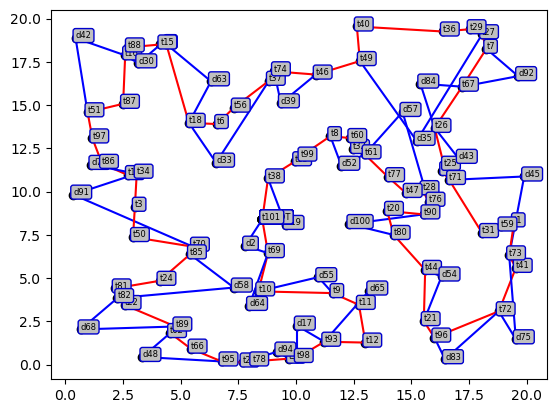

[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only LONG arc), tsp_used
------------------------------------------------------------------------------------------------------------------------


In [4641]:
# ================================
# TSP-D base model (requires ready tT/dT)
# Greedy partition (MakeFly/PushLeft/PushRight)
# Schedule + True Makespan (truck path + waits + SL + SR)
# PERFECT INFORMATION version:
#   - Regional disruption constraints imposed FROM THE START (using Reg, TCon)
#   - NO DRN (Drone Rescue Node) constraint
#
# IMPORTANT FIX (Feb 2026):
#   Fixes the “weird 3-node path” bug where the end depot appears immediately
#   after the start depot in the truck cycle, causing:
#     Labels along path: OrderedDict([(0,...),(19,...),(101,...)])
#     True makespan ~ 60 (nonsense)
#
#   The fix chooses the LONGER of the two arcs between depot and end_depot
#   on a cycle (forward vs backward), so you never accidentally measure the
#   tiny arc 0 -> ... -> end.
#
# Assumes you define BEFORE running:
#   V1, tsp1 (Concorde tour optional), tT, dT, Reg, TCon
# ================================

import sys, time as _time
import numpy as _np
import numpy
from collections import OrderedDict, defaultdict

# ---------- Reproducibility ----------
SEED = 1923
SAMPLE_RATIO = 0.05  # for tour local search (sampled neighbors)

# ---------- Service times ----------
SL = 1.0   # launch service (0 at depot)
SR = 1.0   # recovery service at rendezvous

# ---------- Mission energy/feasibility limit (time) ----------
E_LIMIT = 40.0

# ---------- Optional drawing ----------
DRAW_ROUTES = True
sys.path.append("../")
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Travel-time accessors (REQUIRES ready tT/dT)
# =========================================================
def _ensure_travel_times():
    global tT, dT
    assert isinstance(tT, dict) and isinstance(dT, dict), \
        "You must predefine ready dicts tT and dT before running."

def truck_time(i, j):  # symmetric lookup ok
    try: return tT[(i, j)]
    except KeyError: return tT[(j, i)]

def drone_time(i, j):
    try: return dT[(i, j)]
    except KeyError: return dT[(j, i)]

# =========================================================
# PERFECT-INFO DISRUPTION CHECKS (Reg, TCon must exist)
# =========================================================
def _ensure_disruption_data():
    global Reg, TCon, V1
    assert "Reg" in globals() and Reg is not None, "Define Reg (region index per node) before running."
    assert "TCon" in globals() and TCon is not None, "Define TCon (region -> (start,end)) before running."
    assert len(Reg) == len(V1), "Reg must have length len(V1)."

def is_in_disruption(region_idx, t):
    """
    True if time t is inside the disruption window of region_idx.
    Region 0 / None = no disruption.
    """
    if region_idx is None or region_idx <= 0:
        return False
    start, end = TCon[region_idx]
    return (t >= start) and (t <= end)

def disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
    """
    Enforce regional disruption constraints (perfect information).
    We require that key event times are NOT inside disruption windows:
      - launch completion time at L  (drone_times[L][1])
      - drone arrival at drone customer d (drone_times[d][0])
      - drone arrival at rendezvous R (drone_times[R][0])
    """
    _ensure_disruption_data()
    global Reg

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            return False

        if is_in_disruption(Reg[L], drone_times[L][1]):  # after SL
            return False
        if is_in_disruption(Reg[d], drone_times[d][0]):  # arrival at customer
            return False
        if is_in_disruption(Reg[R], drone_times[R][0]):  # arrival at rendezvous
            return False

    return True

# =========================================================
# Schedule (truck_times, drone_times)
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    truck_path = [u for u in tsp if label.get(u, 'combined') != 'drone']

    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times, drone_times = {}, {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    # launches at start
    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start
            R = drone_mission[d][1]
            sl = 0.0 if L == depot else SL
            t += sl
            truck_times[L][1] = t

            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]

            d_arr = t + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    # traverse
    for k in range(1, len(truck_path)):
        prev = truck_path[k - 1]
        cur  = truck_path[k]

        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        # recoveries
        if cur in missions_by_R:
            latest = max(drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time) \
                     if missions_by_R[cur] else t
            if latest > t:
                t = latest
            t += SR
            truck_times[cur][1] = t

            for d in missions_by_R[cur]:
                if d in drone_R_time:
                    drone_times[cur] = [drone_R_time[d], t]

        # launches at cur
        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur
                R = drone_mission[d][1]
                sl = 0.0 if L == depot else SL

                t += sl
                truck_times[L][1] = t

                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)

                d_arr = t + drone_time(L, d)
                R_arr = d_arr + drone_time(d, R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times

# =========================================================
# Greedy partition: MakeFly / PushLeft / PushRight
# (UPDATED: checks disruption feasibility after each accepted move)
# =========================================================
def greedy_partitioning(tsp, depot, V1):
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(tsp)
    end_depot = len(V1) - 1

    ND = {4, 5, 10, 15, 20, depot, end_depot}  # forbidden drone-only customers

    label = {}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}  # d -> (L,R)

    # base truck tour cost around cycle
    tsptotal = 0.0
    for k in range(n):
        i, j = tsp[k], tsp[(k + 1) % n]
        label[i] = 'simple'
        tsptotal += truck_time(i, j)
    tspdtotal = tsptotal

    MAX_ATTEMPTS_PER_OUTER = max(10, 10 * n)

    while 'simple' in label.values():
        banned = set()  # (block,pos) pairs that violated disruption after applying
        attempts = 0

        while True:
            attempts += 1
            if attempts > MAX_ATTEMPTS_PER_OUTER:
                for u in label:
                    if label[u] == 'simple':
                        label[u] = 'combined'
                break

            ms = []
            idx_map = []  # each entry maps to (block,pos)

            # 1) Make Fly
            for i in range(n):
                if (0, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((0, i))
                    continue

                saving = -float('inf')
                u = tsp[i]
                if label[u] == 'simple' and u not in ND:
                    L = tsp[i - 1]
                    R = tsp[(i + 1) % n]
                    fly_time = drone_time(L, u) + drone_time(u, R)

                    if fly_time + SL <= E_LIMIT and truck_time(L, R) <= E_LIMIT:
                        base = truck_time(L, u) + truck_time(u, R)
                        alt  = max(fly_time, truck_time(L, R) + SL + SR)
                        saving = base - alt

                ms.append(saving)
                idx_map.append((0, i))

            # 2) Push Left
            for i in range(n):
                if (1, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((1, i))
                    continue

                saving = -float('inf')
                cur = tsp[i]
                prev = tsp[i - 1]

                if label.get(prev) == 'combined' and prev != depot and label.get(cur) == 'simple':
                    j = i - 2
                    dronenode = None
                    while label[tsp[j]] != 'combined':
                        if label[tsp[j]] == 'drone':
                            dronenode = j
                        if label[tsp[j - 1]] == 'combined' and dronenode is not None:
                            d = tsp[dronenode]
                            L = tsp[j - 1]
                            R_old = prev
                            R_new = cur
                            base_key = (d, L, R_old)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new   = drone_time(L, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(R_old, R_new)
                                if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                    saving = truck_time(R_old, R_new) + operation[base_key] - \
                                             max(fly_new, drive_new + SR)
                            break
                        j -= 1

                ms.append(saving)
                idx_map.append((1, i))

            # 3) Push Right
            for i in range(n):
                if (2, i) in banned:
                    ms.append(-float('inf'))
                    idx_map.append((2, i))
                    continue

                saving = -float('inf')
                cur = tsp[i]
                nxt = tsp[(i + 1) % n]

                if label.get(nxt) == 'combined' and nxt != depot and label.get(cur) == 'simple':
                    j = (i + 2) % n
                    dronenode = None
                    while label[tsp[j]] != 'combined':
                        if label[tsp[j]] == 'drone':
                            dronenode = j
                        if label[tsp[(j + 1) % n]] == 'combined' and dronenode is not None:
                            d = tsp[dronenode]
                            L_old = nxt
                            R_new = tsp[(j + 1) % n]
                            base_key = (d, L_old, R_new)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new   = drone_time(cur, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(cur, L_old)
                                if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                    saving = truck_time(cur, L_old) + operation[base_key] - \
                                             max(fly_new, drive_new + SR)
                            break
                        j = (j + 1) % n

                ms.append(saving)
                idx_map.append((2, i))

            idx = int(numpy.argmax(ms))
            best_saving = ms[idx]

            if best_saving <= 0 or best_saving == -float('inf'):
                for u in label:
                    if label[u] == 'simple':
                        label[u] = 'combined'
                break

            block, pos = idx_map[idx]

            # backup
            label_b = dict(label)
            drone_b = dict(drone_mission)
            op_b = dict(operation)
            flyop_b = dict(flyop)
            driveop_b = dict(driveop)
            tspd_b = tspdtotal

            # apply
            tspdtotal -= best_saving

            if block == 0:
                d = tsp[pos]
                L = tsp[pos - 1]
                R = tsp[(pos + 1) % n]
                label[d] = 'drone'
                label[L] = 'combined'
                label[R] = 'combined'
                flyop[(d, L, R)] = drone_time(L, d) + drone_time(d, R)
                driveop[(d, L, R)] = truck_time(L, R)
                operation[(d, L, R)] = max(flyop[(d, L, R)], driveop[(d, L, R)])
                drone_mission[d] = (L, R)

            elif block == 1:
                label[tsp[pos]] = 'combined'
                label[tsp[(pos - 1) % n]] = 'truck'
                j = (pos - 2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[j - 1]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L = tsp[j - 1]
                        R_new = tsp[pos]
                        prev_R = tsp[(pos - 1) % n]
                        flyop[(d, L, R_new)] = drone_time(L, d) + drone_time(d, R_new)
                        driveop[(d, L, R_new)] = driveop[(d, L, prev_R)] + truck_time(prev_R, R_new)
                        operation[(d, L, R_new)] = max(flyop[(d, L, R_new)], driveop[(d, L, R_new)])
                        drone_mission[d] = (L, R_new)
                        break
                    j -= 1

            else:
                label[tsp[pos]] = 'combined'
                label[tsp[(pos + 1) % n]] = 'truck'
                j = (pos + 2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[(j + 1) % n]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L_new = tsp[pos]
                        R = tsp[(j + 1) % n]
                        next_L = tsp[(pos + 1) % n]
                        flyop[(d, L_new, R)] = drone_time(L_new, d) + drone_time(d, R)
                        driveop[(d, L_new, R)] = driveop[(d, next_L, R)] + truck_time(L_new, next_L)
                        operation[(d, L_new, R)] = max(flyop[(d, L_new, R)], driveop[(d, L_new, R)])
                        drone_mission[d] = (L_new, R)
                        break
                    j = (j + 1) % n

            # disruption feasibility check via schedule
            truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
            if disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                break
            else:
                # rollback + ban that move
                label = label_b
                drone_mission = drone_b
                operation = op_b
                flyop = flyop_b
                driveop = driveop_b
                tspdtotal = tspd_b
                banned.add((block, pos))
                continue

    dset = {u for u in label if label[u] == 'drone'}
    return tspdtotal, label, dset, drone_mission, operation, flyop, driveop

# =========================================================
# FIXED PATH EXTRACTION (prevents “3-node path” bug)
# =========================================================
def linearize_between_depots_longest(tour, start_depot, end_depot):
    """
    FIX:
    tour is a cycle. There are two arcs start->end (forward & backward).
    Pick the LONGER arc so we don't accidentally choose a tiny arc
    when end_depot appears right after start_depot in the cycle.
    """
    n = len(tour)
    i = tour.index(start_depot)

    # forward arc
    forward = [start_depot]
    j = (i + 1) % n
    while tour[j] != end_depot:
        forward.append(tour[j])
        j = (j + 1) % n
    forward.append(end_depot)

    # backward arc
    backward = [start_depot]
    j = (i - 1) % n
    while tour[j] != end_depot:
        backward.append(tour[j])
        j = (j - 1) % n
    backward.append(end_depot)

    return forward if len(forward) >= len(backward) else backward

# =========================================================
# True makespan (your formula) helpers
# =========================================================
def truck_path_time_0_to_end(tsp, label, start_depot, end_depot):
    truck_cycle = [u for u in tsp if label.get(u, 'combined') != 'drone']

    # -------- FIX APPLIED HERE --------
    path = linearize_between_depots_longest(truck_cycle, start_depot, end_depot)
    # ---------------------------------

    total = 0.0
    for i in range(1, len(path)):
        total += truck_time(path[i - 1], path[i])
    return total, path

def compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=None):
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        if depot is not None and R == depot:
            continue
        missions_by_R[R].append((d, L))

    wait = {}
    for R, pairs in missions_by_R.items():
        if R not in truck_times:
            continue
        t_truck_arr = truck_times[R][0]
        latest_R_arr = float("-inf")
        for d, L in pairs:
            tL = drone_times[L][1]
            d_arr = tL + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            latest_R_arr = max(latest_R_arr, R_arr)
        wait[R] = max(0.0, latest_R_arr - t_truck_arr)
    return wait

def count_launches_excluding_depot(drone_mission, depot):
    return sum(1 for d, (L, _) in drone_mission.items() if L != depot)

def true_makespan_from_formula(tsp, label, truck_times, drone_times, drone_mission, depot, end_depot):
    truck_travel_sum, _truck_path = truck_path_time_0_to_end(tsp, label, depot, end_depot)
    waits = compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=depot)
    total_wait = sum(waits.values())
    launches_excl_depot = count_launches_excluding_depot(drone_mission, depot)
    recoveries = len(drone_mission)
    return truck_travel_sum + total_wait + SL * launches_excl_depot + SR * recoveries

# =========================================================
# Tour LS (sampled neighbors)
# =========================================================
def two_points_move(route, i, j):
    r = route[:]
    r[i], r[j] = r[j], r[i]
    return r

def two_opt_move(route, i, j):
    if i > j: i, j = j, i
    return route[:i + 1] + route[i + 1:j + 1][::-1] + route[j + 1:]

def one_point_move(route, i, j):
    if i == j: return route[:]
    r = route[:]
    node = r.pop(i)
    r.insert(j, node)
    return r

def _rotate_to_depot(route, depot):
    if route[0] == depot: return route
    k = route.index(depot)
    return route[k:] + route[:k]

def improve_all(heuristic, route_in, depot, V1, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(route_in)
    route_best = _rotate_to_depot(list(route_in), depot)
    cache = {}

    def eval_route(rt):
        key = tuple(rt)
        if key in cache:
            return cache[key]
        rt0 = _rotate_to_depot(rt, depot)
        val = heuristic(rt0, depot, V1)[0]
        cache[key] = val
        return val

    f_best = eval_route(route_best)
    if rng_seed is not None:
        _np.random.seed(rng_seed)

    all_pairs = [(i, j) for i in range(n) for j in range(n) if j != i]
    m = len(all_pairs)
    k = max(1, int(round(sample_ratio * m)))

    improved = True
    while improved:
        improved = False
        idxs = _np.random.choice(m, size=k, replace=False)
        best_neighbor, best_cost = None, f_best

        for p in idxs:
            i, j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = _rotate_to_depot(mv(route_best, i, j), depot)
                fc = eval_route(cand)
                if fc < best_cost - 1e-12:
                    best_neighbor, best_cost = cand, fc

        if best_neighbor is not None:
            route_best, f_best, improved = best_neighbor, best_cost, True

    return route_best

# =========================================================
# Wrapper: seed tour -> LS -> partition -> schedule
# =========================================================
def two_opt_greedy_partitioning_all_improved(V1, depot, tsp_init=None):
    _ensure_travel_times()
    _ensure_disruption_data()

    n = len(V1)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
    else:
        try:
            from __main__ import tsp1
            tsp_seed = list(tsp1)
            print("[INFO] Using Concorde tour (tsp1) as initial tour.")
        except Exception:
            tsp_seed = two_opt_for_TSP(V1)
            print("[INFO] Concorde tsp1 not found; using 2-opt seed.")

    if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
        raise ValueError("Initial tour must be a permutation of 0..n-1 with length len(V1).")

    tsp_seed = _rotate_to_depot(tsp_seed, depot)

    tsp_best = improve_all(greedy_partitioning, tsp_seed, depot, V1,
                           sample_ratio=SAMPLE_RATIO, rng_seed=SEED)

    total_cost, label, drone_nodes, drone_mission, operation, flyop, driveop = greedy_partitioning(
        tsp_best, depot, V1
    )

    truck_times, drone_times = compute_arrival_times(tsp_best, depot, label, drone_mission)

    if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
        print("[WARN] Final solution violates disruption constraints (should be rare).")

    return (total_cost, label, drone_nodes, drone_mission, truck_times, drone_times), tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    global V1
    _ensure_travel_times()
    _ensure_disruption_data()

    depot = 0
    END_DEPOT = len(V1) - 1
    _np.random.seed(SEED)

    print("-" * 120)

    try:
        from __main__ import tsp1
        tsp_init = tsp1
    except Exception:
        tsp_init = None

    start = _time.time()
    (total_cost,
     label,
     drone_nodes,
     drone_mission,
     truck_times,
     drone_times), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, tsp_init=tsp_init
    )
    end = _time.time()

    f_true = true_makespan_from_formula(
        tsp_used, label, truck_times, drone_times, drone_mission, depot, END_DEPOT
    )

    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print("----------------------------")
    print(f"True makespan from schedule: {f_true:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print(f"Running time: {end - start:.4f} sec")
    print("TCon is:", TCon)
    print("SEED is:", SEED)
    print("SAMPLE_RATIO is:", SAMPLE_RATIO)
    if "START" in globals() and "DURATION" in globals():
        print("START is = ", START, "DURATION is = ", DURATION)
    print("----------------------------")

    # -------- FIX APPLIED HERE (labels printed on LONG arc) --------
    tsp_path_0_to_end = linearize_between_depots_longest(tsp_used, depot, END_DEPOT)
    # --------------------------------------------------------------
    label_path_only = OrderedDict((u, label[u]) for u in tsp_path_0_to_end)

    print("Labels along *path* (0 -> ... -> end) [FIXED]:")
    print(label_path_only)

    # Optional drawing
    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    # Export for later
    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["drone_mission"] = drone_mission

    # NOTE: we still export path-only labels, but now they are the LONG arc path
    globals()["label"] = dict(label_path_only)
    globals()["tsp_used"] = tsp_used

    print("[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only LONG arc), tsp_used")
    print("-" * 120)

if __name__ == "__main__":
    main()


In [4642]:
#ALTERNATIVE ABOVE

In [4643]:
#PERF INFO SCENARIO UP TO HERE
#PERF INFO SCENARIO UP TO HERE
#PERF INFO SCENARIO UP TO HERE

In [4644]:
drone_times

{0: [0.0, 0.0],
 38: [6.608195367735472, 7.608195367735472],
 13: [0.0, 0.0],
 99: [0.0, 0.0],
 8: [19.94419536773547, 20.94419536773547],
 60: [0.0, 0.0],
 32: [0.0, 0.0],
 61: [26.0572499045929, 29.04019536773547],
 77: [0.0, 0.0],
 47: [0.0, 0.0],
 28: [0.0, 0.0],
 76: [43.19990027042874, 44.19990027042874],
 90: [46.47990027042874, 47.47990027042874],
 20: [0.0, 0.0],
 80: [56.5299555886012, 57.5299555886012],
 44: [65.64195558860119, 66.64195558860119],
 21: [72.63809397266569, 74.8899555886012],
 96: [78.2739555886012, 79.2739555886012],
 72: [87.76240299226438, 91.61795558860119],
 41: [0.0, 0.0],
 73: [103.00025270214078, 105.00025270214078],
 1: [0.0, 0.0],
 59: [0.0, 0.0],
 31: [0.0, 0.0],
 71: [118.47838153777369, 126.6882527021408],
 5: [0.0, 0.0],
 25: [129.5682527021408, 130.5682527021408],
 26: [135.4196014170402, 138.8082527021408],
 67: [146.44185831614993, 149.3762527021408],
 7: [157.26745709200534, 158.26745709200534],
 27: [160.71545709200535, 161.71545709200535],


In [4645]:
for i in drone_times:
    if drone_times[i][0] > 0:
        print (i,"is in the region:", Reg[i], "Time constraint is:", TCon[Reg[i]], "and actual drone times are:", drone_times[i])

38 is in the region: 3 Time constraint is: [272, 308] and actual drone times are: [6.608195367735472, 7.608195367735472]
8 is in the region: 3 Time constraint is: [272, 308] and actual drone times are: [19.94419536773547, 20.94419536773547]
61 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [26.0572499045929, 29.04019536773547]
76 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [43.19990027042874, 44.19990027042874]
90 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [46.47990027042874, 47.47990027042874]
80 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [56.5299555886012, 57.5299555886012]
44 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [65.64195558860119, 66.64195558860119]
21 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [72.63809397266569, 74.8899555886012]
96 is in the region: 4 Time constrain

In [4646]:
for i in drone_times:
    if drone_times[i][0] > 0:
        if drone_times[i][0] <= TCon[Reg[i]][0] or drone_times[i][0] >= TCon[Reg[i]][1] and drone_times[i][1] <= TCon[Reg[i]][0] or drone_times[i][1] >= TCon[Reg[i]][1]:
            print (i,"is in the region:", Reg[i], "Time constraint is:", TCon[Reg[i]], "and actual drone times are:", drone_times[i], "PASSED NO PROBLEM")
        else:
            print (i,"is in the region:", Reg[i], "Time constraint is:", TCon[Reg[i]], "and actual drone times are:", drone_times[i], "THERE IS A PROBLEM")

38 is in the region: 3 Time constraint is: [272, 308] and actual drone times are: [6.608195367735472, 7.608195367735472] PASSED NO PROBLEM
8 is in the region: 3 Time constraint is: [272, 308] and actual drone times are: [19.94419536773547, 20.94419536773547] PASSED NO PROBLEM
61 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [26.0572499045929, 29.04019536773547] PASSED NO PROBLEM
76 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [43.19990027042874, 44.19990027042874] PASSED NO PROBLEM
90 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [46.47990027042874, 47.47990027042874] PASSED NO PROBLEM
80 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [56.5299555886012, 57.5299555886012] PASSED NO PROBLEM
44 is in the region: 4 Time constraint is: [308, 344] and actual drone times are: [65.64195558860119, 66.64195558860119] PASSED NO PROBLEM
21 is in the region: 4 Time con

In [4647]:
#TCon =  [[0, 0], [50,62],[62,74],[74,86],[86,98],[98,110]]#disruption duration 
#TCon =  [[0, 0], [50,74],[74,98],[98,122],[122,146],[146,170]]#disruption duration 
#TCon =  [[0, 0], [50,86],[86,122],[122,158],[158,194],[194,230]]#disruption duration 

In [4648]:
wwww = [[[0, 0], [50,62],[62,74],[74,86],[86,98],[98,110]], [[0, 0], [50,74],[74,98],[98,122],[122,146],[146,170]], [[0, 0], [50,86],[86,122],[122,158],[158,194],[194,230]]]